In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from sqlalchemy import create_engine, event, text
from sqlalchemy.engine import URL

ROOT = r'D:\Bluestock work\bluestock-fintech-analysis1'
RAW_DIR = os.path.join(ROOT, 'data', 'raw')
PROCESSED_DIR = os.path.join(ROOT, 'data', 'processed')
REPORTS_DIR = os.path.join(ROOT, 'reports')
DB_PATH = os.path.join(PROCESSED_DIR, 'bluestock_dw.db')

TRADING_DAYS = 252

engine = create_engine(URL.create('sqlite', database=DB_PATH))

@event.listens_for(engine, 'connect')
def turn_on_foreign_keys(dbapi_connection, connection_record):
    cursor = dbapi_connection.cursor()
    cursor.execute('PRAGMA foreign_keys = ON')
    cursor.close()

In [12]:
needed = {
    'fund_cagr_comparison.csv': 'Task 15',
    'fund_risk_adjusted_returns.csv': 'Task 16',
    'fund_alpha_beta.csv': 'Task 17',
    'fund_max_drawdown.csv': 'Task 17',
}

missing = []
for file_name, task in needed.items():
    exists = os.path.exists(os.path.join(PROCESSED_DIR, file_name))
    print(file_name, '|', task, '| found:', exists)
    if not exists:
        missing.append(file_name)

assert not missing, 'Missing files: ' + ', '.join(missing) + '. Finish the earlier task first.'

cagr = pd.read_csv(os.path.join(PROCESSED_DIR, 'fund_cagr_comparison.csv'))[['amfi_code', 'cagr_3yr_pct']]
sharpe = pd.read_csv(os.path.join(PROCESSED_DIR, 'fund_risk_adjusted_returns.csv'))[['amfi_code', 'sharpe']]
alpha = pd.read_csv(os.path.join(PROCESSED_DIR, 'fund_alpha_beta.csv'))[['amfi_code', 'alpha_ann_pct']]
drawdown = pd.read_csv(os.path.join(PROCESSED_DIR, 'fund_max_drawdown.csv'))[['amfi_code', 'max_drawdown_pct']]

expense = pd.read_sql_query('SELECT amfi_code, expense_ratio_pct FROM fact_performance', engine)
funds = pd.read_sql_query(
    'SELECT amfi_code, scheme_name, fund_house, category, plan, benchmark FROM dim_fund', engine)

scorecard = funds.merge(cagr, on='amfi_code', how='inner')
for part in [sharpe, alpha, drawdown, expense]:
    scorecard = scorecard.merge(part, on='amfi_code', how='left')

COMPONENTS = ['cagr_3yr_pct', 'sharpe', 'alpha_ann_pct', 'expense_ratio_pct', 'max_drawdown_pct']

print()
print('Funds:', len(scorecard), '| repeated amfi_code:', scorecard['amfi_code'].duplicated().sum())
print(scorecard[COMPONENTS].notnull().sum())

fund_cagr_comparison.csv | Task 15 | found: True
fund_risk_adjusted_returns.csv | Task 16 | found: True
fund_alpha_beta.csv | Task 17 | found: True
fund_max_drawdown.csv | Task 17 | found: True

Funds: 40 | repeated amfi_code: 0
cagr_3yr_pct         40
sharpe               40
alpha_ann_pct        40
expense_ratio_pct    40
max_drawdown_pct     40
dtype: int64


In [9]:
WEIGHTS = {'cagr_3yr_pct': 30, 'sharpe': 25, 'alpha_ann_pct': 20,
           'expense_ratio_pct': 15, 'max_drawdown_pct': 10}

HIGHER_IS_BETTER = {'cagr_3yr_pct': True, 'sharpe': True, 'alpha_ann_pct': True,
                    'expense_ratio_pct': False, 'max_drawdown_pct': True}

assert sum(WEIGHTS.values()) == 100, 'The weights must add to 100'


def points_for(series, higher_is_better=True):
    n = series.notnull().sum()
    if n < 2:
        return pd.Series(np.nan, index=series.index)
    rank = series.rank(ascending=not higher_is_better, method='average')
    return 100 * (n - rank) / (n - 1)


def points_by_group(series, groups, higher_is_better=True):
    return series.groupby(groups).transform(points_for, higher_is_better=higher_is_better)


# Tests with the examples from Part 1
print(points_for(pd.Series([12.0, 8.0, 15.0, 10.0, 9.0])).tolist())
print(points_for(pd.Series([1.0, 2.0, 0.5]), higher_is_better=False).tolist())

[75.0, 0.0, 100.0, 50.0, 25.0]
[50.0, 0.0, 100.0]


In [13]:
pts_cols = []
for col in COMPONENTS:
    scorecard['pts_' + col] = points_for(scorecard[col], HIGHER_IS_BETTER[col])
    pts_cols.append('pts_' + col)

complete = scorecard[pts_cols].notnull().all(axis=1)

score = 0
for col in COMPONENTS:
    score = score + scorecard['pts_' + col] * WEIGHTS[col] / 100

scorecard['complete'] = complete
scorecard['score'] = score.where(complete)
scorecard['score_rank'] = scorecard['score'].rank(ascending=False, method='min')

# The same score, but ranked inside each category
score_in_category = 0
for col in COMPONENTS:
    pts = points_by_group(scorecard[col], scorecard['category'], HIGHER_IS_BETTER[col])
    score_in_category = score_in_category + pts * WEIGHTS[col] / 100

scorecard['score_in_category'] = score_in_category.where(complete)
scorecard['rank_in_category'] = (
    scorecard.groupby('category')['score_in_category'].rank(ascending=False, method='min'))

print('Funds with a score:', int(complete.sum()), 'of', len(scorecard))
print('Funds with no score (a part is missing):', int((~complete).sum()))

Funds with a score: 40 of 40
Funds with no score (a part is missing): 0


In [14]:
# Check A
valid = scorecard['score'].dropna()
print('A. Scores from', round(valid.min(), 1), 'to', round(valid.max(), 1),
      '| all between 0 and 100:', bool(valid.between(0, 100).all()))

# Check B
row = scorecard[scorecard['complete']].iloc[0]
hand = 0
for col in COMPONENTS:
    values = scorecard[col].dropna().to_numpy()
    ranks = rankdata(-values if HIGHER_IS_BETTER[col] else values)
    own_rank = ranks[np.where(values == row[col])[0][0]]
    hand = hand + 100 * (len(values) - own_rank) / (len(values) - 1) * WEIGHTS[col] / 100

print('B. Fund:', row['scheme_name'], '| by hand:', round(hand, 4), '| in the table:', round(row['score'], 4))
print('   Same value:', np.isclose(hand, row['score']))

# Check C
lowest_expense = scorecard.loc[scorecard['expense_ratio_pct'].idxmin()]
shallowest = scorecard.loc[scorecard['max_drawdown_pct'].idxmax()]
print('C. Lowest expense ratio gets', round(lowest_expense['pts_expense_ratio_pct'], 1), 'points.')
print('   Shallowest drawdown gets', round(shallowest['pts_max_drawdown_pct'], 1), 'points.')

A. Scores from 12.1 to 85.9 | all between 0 and 100: True
B. Fund: HDFC Top 100 Fund - Regular Plan - Growth | by hand: 12.1795 | in the table: 12.1795
   Same value: True
C. Lowest expense ratio gets 100.0 points.
   Shallowest drawdown gets 100.0 points.


In [15]:
equal_score = scorecard[pts_cols].mean(axis=1).where(complete)

rho = scorecard['score'].corr(equal_score, method='spearman')
top5_task = set(scorecard.nlargest(5, 'score')['amfi_code'])
top5_equal = set(scorecard.loc[equal_score.nlargest(5).index, 'amfi_code'])

print('Rank correlation, task weights vs equal weights:', round(rho, 2))
print('Funds in both top 5 lists:', len(top5_task & top5_equal), 'of 5')
print()
print('Correlation of the points of the five parts:')
print(scorecard[pts_cols].corr().round(2))

Rank correlation, task weights vs equal weights: 0.97
Funds in both top 5 lists: 5 of 5

Correlation of the points of the five parts:
                       pts_cagr_3yr_pct  pts_sharpe  pts_alpha_ann_pct  \
pts_cagr_3yr_pct                   1.00        0.88               0.88   
pts_sharpe                         0.88        1.00               0.93   
pts_alpha_ann_pct                  0.88        0.93               1.00   
pts_expense_ratio_pct             -0.20       -0.31              -0.30   
pts_max_drawdown_pct               0.09        0.05              -0.03   

                       pts_expense_ratio_pct  pts_max_drawdown_pct  
pts_cagr_3yr_pct                       -0.20                  0.09  
pts_sharpe                             -0.31                  0.05  
pts_alpha_ann_pct                      -0.30                 -0.03  
pts_expense_ratio_pct                   1.00                  0.28  
pts_max_drawdown_pct                    0.28                  1.00  


 score_rank                                           scheme_name category    plan  score  pts_cagr_3yr_pct  pts_sharpe  pts_alpha_ann_pct  pts_expense_ratio_pct  pts_max_drawdown_pct  score_in_category  rank_in_category  complete
        1.0         Mirae Asset Large Cap Fund - Regular - Growth   Equity Regular   85.9              97.4       100.0               84.6                   43.6                  82.1               87.9               1.0      True
        2.0              ICICI Pru Midcap Fund - Regular - Growth   Equity Regular   81.8              89.7        89.7               94.9                   64.1                  38.5               83.0               2.0      True
        3.0                Kotak Flexicap Fund - Regular - Growth   Equity Regular   81.5              84.6        97.4               89.7                   46.2                  69.2               82.7               3.0      True
        4.0    HDFC Mid-Cap Opportunities Fund - Regular - Growth   Equity R

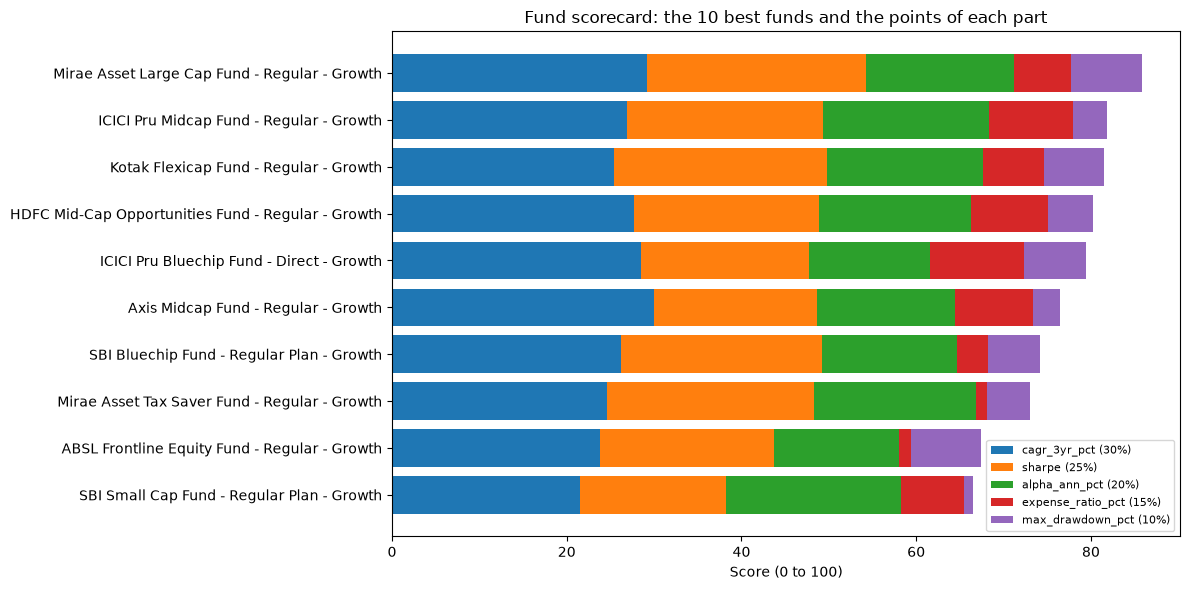

Saved fund_scorecard.csv: 40 rows


In [16]:
view = scorecard.sort_values('score', ascending=False)
show = ['score_rank', 'scheme_name', 'category', 'plan', 'score'] + pts_cols + [
    'score_in_category', 'rank_in_category', 'complete']
print(view[show].round(1).to_string(index=False))

top10 = view.dropna(subset=['score']).head(10).iloc[::-1]
left = np.zeros(len(top10))

plt.figure(figsize=(12, 6))
for col in COMPONENTS:
    piece = (top10['pts_' + col] * WEIGHTS[col] / 100).to_numpy()
    plt.barh(top10['scheme_name'], piece, left=left, label=col + ' (' + str(WEIGHTS[col]) + '%)')
    left = left + piece

plt.xlabel('Score (0 to 100)')
plt.title('Fund scorecard: the 10 best funds and the points of each part')
plt.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, 'fund_scorecard_breakdown.png'))
plt.show()

out_cols = ['score_rank', 'amfi_code', 'scheme_name', 'fund_house', 'category', 'plan', 'benchmark',
            'complete', 'score'] + COMPONENTS + pts_cols + ['score_in_category', 'rank_in_category']
view[out_cols].round(4).to_csv(os.path.join(PROCESSED_DIR, 'fund_scorecard.csv'), index=False)
print('Saved fund_scorecard.csv:', len(view), 'rows')

In [17]:
bench_path = glob.glob(os.path.join(RAW_DIR, '*10_benchmark_indices*'))[0]
bench = pd.read_csv(bench_path)

bench['index_key'] = (bench['index_name'].astype(str).str.lower()
                      .str.replace(r'[^a-z0-9]', '', regex=True))

print(bench.groupby('index_key')['index_name'].agg(['first', 'count']))
print()
print(bench['date'].head().tolist())

                          first  count
index_key                             
bsesmallcap        BSE_SMALLCAP   1150
crisilgilt          CRISIL_GILT   1150
crisilliquid      CRISIL_LIQUID   1150
nifty100               NIFTY100   1150
nifty50                 NIFTY50   1150
nifty500               NIFTY500   1150
niftymidcap150  NIFTY_MIDCAP150   1150

['2022-01-03', '2022-01-04', '2022-01-05', '2022-01-06', '2022-01-07']


In [18]:
NIFTY50_KEY = 'nifty50'
NIFTY100_KEY = 'nifty100'
DATE_FORMAT = '%Y-%m-%d'


def load_index(key):
    part = bench[bench['index_key'] == key].copy()
    assert len(part) > 0, 'No rows for key ' + key + '. Check the list in Part A.'

    part['date'] = pd.to_datetime(part['date'], format=DATE_FORMAT, errors='coerce')
    part['close_value'] = pd.to_numeric(
        part['close_value'].astype(str).str.replace(',', '', regex=False), errors='coerce')

    problems = (part['date'].isnull().sum() + part['close_value'].isnull().sum()
                + (part['close_value'] <= 0).sum())

    part = part.dropna(subset=['date', 'close_value'])
    part = part[part['close_value'] > 0]
    part = part.drop_duplicates(subset=['date'], keep='last').sort_values('date')
    assert len(part) > 0, 'All rows were removed for ' + key + '. Check DATE_FORMAT.'

    print(key, '| rows:', len(part), '| problem values:', problems,
          '|', part['date'].min().date(), 'to', part['date'].max().date())
    return part.set_index('date')['close_value']


close50 = load_index(NIFTY50_KEY)
close100 = load_index(NIFTY100_KEY)

daily50 = close50.resample('D').last().ffill(limit=7)
daily100 = close100.resample('D').last().ffill(limit=7)

nifty50 | rows: 1150 | problem values: 0 | 2022-01-03 to 2026-05-29
nifty100 | rows: 1150 | problem values: 0 | 2022-01-03 to 2026-05-29


In [19]:
returns = pd.read_sql_query("""
SELECT r.amfi_code, d.full_date, r.daily_return, r.days_since_prev
FROM fact_daily_return AS r
JOIN dim_date AS d ON d.date_key = r.date_key
ORDER BY r.amfi_code, r.date_key
""", engine)

returns['date'] = pd.to_datetime(returns['full_date'])
returns['prev_date'] = returns['date'] - pd.to_timedelta(returns['days_since_prev'], unit='D')


def index_return(daily):
    close_end = daily.reindex(returns['date']).to_numpy()
    close_start = daily.reindex(returns['prev_date']).to_numpy()
    return close_end / close_start - 1


returns['ret_nifty50'] = index_return(daily50)
returns['ret_nifty100'] = index_return(daily100)

END_DATE = min(returns['date'].max(), close50.index.max(), close100.index.max())
START_3Y = END_DATE - pd.DateOffset(years=3)
print('3-year window:', START_3Y.date(), 'to', END_DATE.date())

eligible = scorecard.loc[scorecard['cagr_3yr_pct'].notnull(), 'amfi_code']

w3 = returns[(returns['date'] > START_3Y) & (returns['date'] <= END_DATE)
             & (returns['amfi_code'].isin(eligible))]
w3 = w3.dropna(subset=['ret_nifty50', 'ret_nifty100'])

w3 = w3.assign(active50=w3['daily_return'] - w3['ret_nifty50'],
               active100=w3['daily_return'] - w3['ret_nifty100'])

root = np.sqrt(TRADING_DAYS)

te = w3.groupby('amfi_code').agg(
    days=('active50', 'count'),
    te_nifty50_pct=('active50', lambda s: s.std() * root * 100),
    te_nifty100_pct=('active100', lambda s: s.std() * root * 100),
    active_nifty50_pct=('active50', lambda s: s.mean() * TRADING_DAYS * 100),
    active_nifty100_pct=('active100', lambda s: s.mean() * TRADING_DAYS * 100),
).reset_index()

te = te.merge(scorecard[['amfi_code', 'scheme_name', 'category', 'benchmark', 'score', 'score_rank']],
              on='amfi_code', how='left')

print('Funds with a tracking error:', len(te))
print(te['days'].describe().round(0))

3-year window: 2023-05-29 to 2026-05-29
Funds with a tracking error: 40
count     40.0
mean     784.0
std        0.0
min      784.0
25%      784.0
50%      784.0
75%      784.0
max      784.0
Name: days, dtype: float64


In [20]:
# Test A
sample_code = int(te['amfi_code'].iloc[0])
sample = w3[w3['amfi_code'] == sample_code]
index_vs_index = (sample['ret_nifty50'] - sample['ret_nifty100']).std() * root * 100
print('A. Tracking error of the Nifty 50 against the Nifty 100:', round(index_vs_index, 2), '%')

# Test B
active = sample['daily_return'].to_numpy() - sample['ret_nifty100'].to_numpy()
hand = active.std(ddof=1) * np.sqrt(252) * 100
table_value = te.loc[te['amfi_code'] == sample_code, 'te_nifty100_pct'].iloc[0]
print('B. Fund', sample_code, '| by hand:', round(hand, 4), '| in the table:', round(table_value, 4))
print('   Same value:', np.isclose(hand, table_value))

A. Tracking error of the Nifty 50 against the Nifty 100: 18.44 %
B. Fund 100016 | by hand: 19.5404 | in the table: 19.5404
   Same value: True


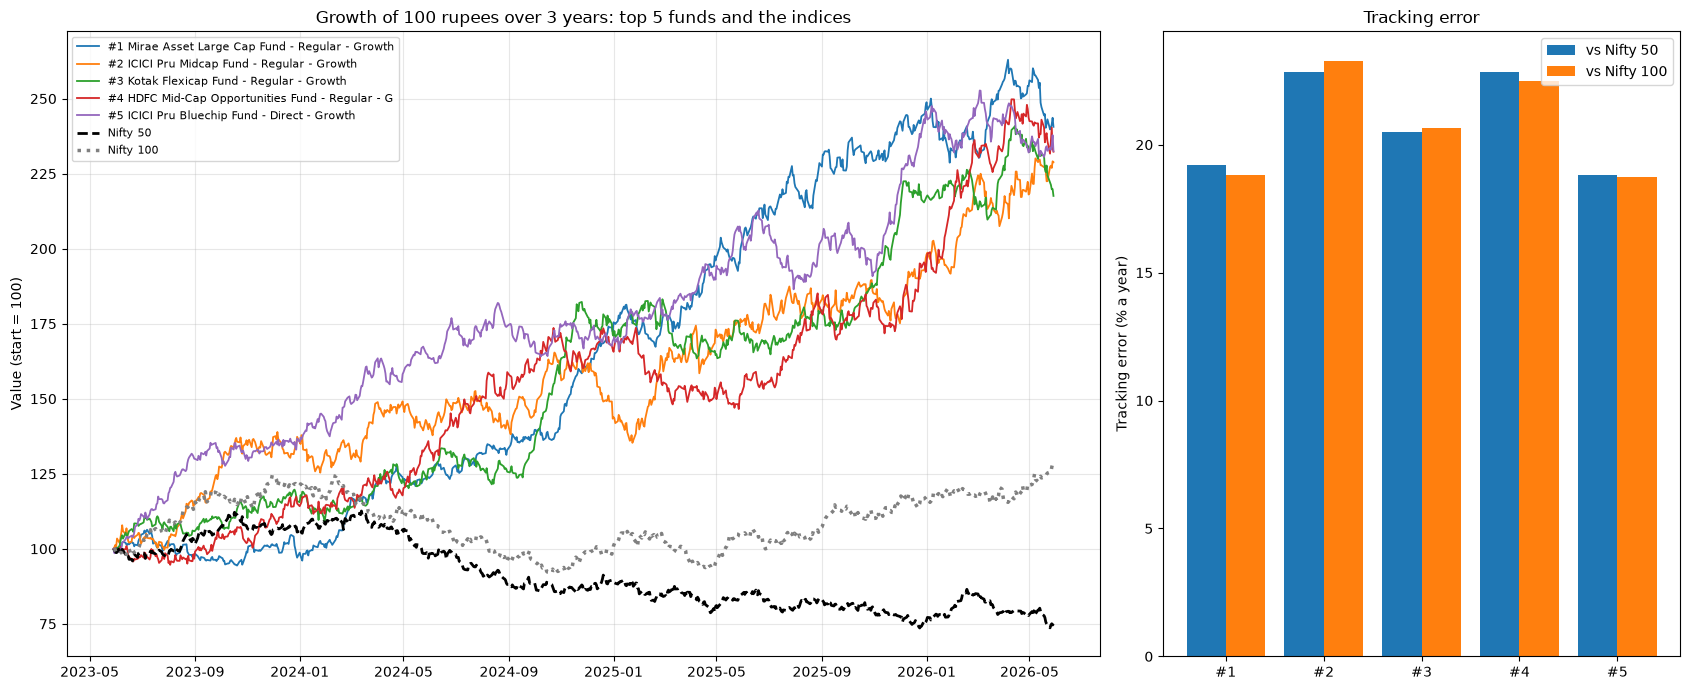

In [21]:
top5 = scorecard.dropna(subset=['score']).nlargest(5, 'score')
top5_codes = top5['amfi_code'].tolist()
names = scorecard.set_index('amfi_code')['scheme_name']

nav = pd.read_sql_query("""
SELECT n.amfi_code, d.full_date, n.nav
FROM fact_nav AS n
JOIN dim_date AS d ON d.date_key = n.date_key
""", engine)
nav['date'] = pd.to_datetime(nav['full_date'])
nav = nav[nav['amfi_code'].isin(top5_codes)]
nav_wide = nav.pivot(index='date', columns='amfi_code', values='nav').sort_index()

trade_dates = close100.loc[START_3Y:END_DATE].index


def rebased(daily_series):
    base = daily_series.reindex([START_3Y]).iloc[0]
    return daily_series.reindex(trade_dates) / base * 100


fig, axes = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={'width_ratios': [2, 1]})

for number, code in enumerate(top5_codes, start=1):
    axes[0].plot(trade_dates, rebased(nav_wide[code]).values, linewidth=1.3,
                 label='#' + str(number) + ' ' + names[code][:45])

axes[0].plot(trade_dates, rebased(daily50).values, color='black', linestyle='--', linewidth=2, label='Nifty 50')
axes[0].plot(trade_dates, rebased(daily100).values, color='gray', linestyle=':', linewidth=2.5, label='Nifty 100')
axes[0].set_title('Growth of 100 rupees over 3 years: top 5 funds and the indices')
axes[0].set_ylabel('Value (start = 100)')
axes[0].legend(loc='upper left', fontsize=8)
axes[0].grid(alpha=0.3)

te_top = te.set_index('amfi_code').loc[top5_codes]
positions = np.arange(len(top5_codes))
axes[1].bar(positions - 0.2, te_top['te_nifty50_pct'], width=0.4, label='vs Nifty 50')
axes[1].bar(positions + 0.2, te_top['te_nifty100_pct'], width=0.4, label='vs Nifty 100')
axes[1].set_xticks(positions)
axes[1].set_xticklabels(['#' + str(number) for number in range(1, len(top5_codes) + 1)])
axes[1].set_ylabel('Tracking error (% a year)')
axes[1].set_title('Tracking error')
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, 'benchmark_comparison.png'), dpi=150)
plt.show()

In [22]:
rows = []
for number, code in enumerate(top5_codes, start=1):
    final = rebased(nav_wide[code]).dropna().iloc[-1]
    rows.append({'rank': number, 'name': names[code][:40], 'value_of_100': final,
                 'cagr_from_chart_pct': ((final / 100) ** (1 / 3) - 1) * 100,
                 'cagr_3yr_task15_pct': scorecard.loc[scorecard['amfi_code'] == code, 'cagr_3yr_pct'].iloc[0]})

for label, daily in [('Nifty 50', daily50), ('Nifty 100', daily100)]:
    final = rebased(daily).dropna().iloc[-1]
    rows.append({'rank': '-', 'name': label, 'value_of_100': final,
                 'cagr_from_chart_pct': ((final / 100) ** (1 / 3) - 1) * 100,
                 'cagr_3yr_task15_pct': np.nan})

print(pd.DataFrame(rows).round(2).to_string(index=False))
print()
print(te_top[['scheme_name', 'category', 'benchmark', 'te_nifty50_pct', 'te_nifty100_pct',
              'active_nifty50_pct', 'active_nifty100_pct']].round(2).to_string(index=False))

rank                                     name  value_of_100  cagr_from_chart_pct  cagr_3yr_task15_pct
   1 Mirae Asset Large Cap Fund - Regular - G        240.62                34.00                34.00
   2 ICICI Pru Midcap Fund - Regular - Growth        228.84                31.78                31.78
   3   Kotak Flexicap Fund - Regular - Growth        217.59                29.58                29.58
   4 HDFC Mid-Cap Opportunities Fund - Regula        232.32                32.44                32.44
   5 ICICI Pru Bluechip Fund - Direct - Growt        232.55                32.49                32.49
   -                                 Nifty 50         75.00                -9.14                  NaN
   -                                Nifty 100        128.53                 8.73                  NaN

                                       scheme_name category            benchmark  te_nifty50_pct  te_nifty100_pct  active_nifty50_pct  active_nifty100_pct
     Mirae Asset Large Cap F

In [23]:
pd.read_csv(os.path.join(PROCESSED_DIR, 'fund_alpha_beta.csv')).to_csv(
    os.path.join(PROCESSED_DIR, 'alpha_beta.csv'), index=False)

te.sort_values('score_rank').round(4).to_csv(
    os.path.join(PROCESSED_DIR, 'tracking_error.csv'), index=False)

best = top5['scheme_name'].tolist()

lines = [
    '# Scorecard and benchmark comparison summary',
    '',
    '- Score (0 to 100) = 30% x 3-year return rank + 25% x Sharpe rank + 20% x alpha rank + 15% x expense ratio rank (inverse) + 10% x max drawdown rank (inverse).',
    '- Each rank is changed to points: 100 x (N - rank) / (N - 1). Rank 1 gets 100 points.',
    f'- Funds with a score: {int(scorecard["complete"].sum())} of {len(scorecard)}. A fund with a missing part has no score.',
    f'- Top 5: {best}.',
    f'- Rank correlation with an equal-weight score: {rho:.2f}. Funds in both top 5 lists: {len(top5_task & top5_equal)} of 5.',
    f'- Benchmark window: {START_3Y.date()} to {END_DATE.date()}. Tracking error = std(fund return - index return) x sqrt(252).',
    f'- Tracking error of the top 5 against the Nifty 50: {te_top["te_nifty50_pct"].round(2).tolist()} (percent a year).',
    f'- Tracking error of the top 5 against the Nifty 100: {te_top["te_nifty100_pct"].round(2).tolist()} (percent a year).',
    '- Checks passed: score between 0 and 100, one fund recomputed with scipy, direction of the inverse parts, index against index, one fund recomputed by hand.',
    '',
    '## Assumptions to confirm with my manager',
    '- A fund with a missing part gets no score.',
    '- All funds are ranked together. See score_in_category for the score inside categories.',
    '- The parts overlap (return, Sharpe, alpha). See the correlation table in the notebook.',
    '- The Nifty 50 and the Nifty 100 are used for every fund. Debt funds and mid or small cap funds have another benchmark.',
    '- The index files may be price indices (no dividends).',
]

summary_text = '\n'.join(lines)

with open(os.path.join(REPORTS_DIR, 'scorecard_benchmark_summary.md'), 'w', encoding='utf-8') as f:
    f.write(summary_text)

deliverables = [
    os.path.join(ROOT, 'notebooks', 'Performance_Analytics.ipynb'),
    os.path.join(PROCESSED_DIR, 'fund_scorecard.csv'),
    os.path.join(PROCESSED_DIR, 'alpha_beta.csv'),
    os.path.join(REPORTS_DIR, 'benchmark_comparison.png'),
]
for path in deliverables:
    print(os.path.exists(path), '|', path)

False | D:\Bluestock work\bluestock-fintech-analysis1\notebooks\Performance_Analytics.ipynb
True | D:\Bluestock work\bluestock-fintech-analysis1\data\processed\fund_scorecard.csv
True | D:\Bluestock work\bluestock-fintech-analysis1\data\processed\alpha_beta.csv
True | D:\Bluestock work\bluestock-fintech-analysis1\reports\benchmark_comparison.png
